# Step:1 Importing Necessary Libraries

#### We will import Numpy, Pandas, Matplotlib, Seaborn, Statsmodels and sklearn library in python.
#### statsmodels: for statistical modeling for fitting logistic regression.
#### sklearn: Provides tools for machine learning modeling.

In [1]:
import pandas as pd
import numpy as np
from sklearn import preprocessing
import matplotlib.pyplot as plt
import seaborn as sns

# Step:2 Data Preparation

#### The dataset is from an ongoing cardiovascular study on residents of the town of Framingham, Massachusetts. The classification goal is to predict whether the patient has 10-year risk of future coronary heart disease (CHD). The dataset provides the patients information. It includes over 4,000 records and 15 attributes.

#### 2.1 Loading

In [2]:
disease_df = pd.read_csv("framingham.csv")

In [3]:
disease_df

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4235,0,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0
4237,0,52,2.0,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0
4238,1,40,3.0,0,0.0,0.0,0,1,0,185.0,141.0,98.0,25.60,67.0,72.0,0


#### Handling Missing Values from the Dataset

In [4]:
disease_df.drop(columns=['education'], inplace = True, axis = 1)
disease_df.rename(columns ={'male':'Sex_male'}, inplace = True)

In [5]:
disease_df.dropna(axis = 0, inplace = True)
disease_df

,Sex_male,age,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4233,1,50,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0,1
4234,1,51,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0,0
4237,0,52,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0
4238,1,40,0,0.0,0.0,0,1,0,185.0,141.0,98.0,25.60,67.0,72.0,0


In [6]:
print(disease_df.TenYearCHD.value_counts())

TenYearCHD
0    3179
1     572
Name: count, dtype: int64


# Step:3 Splitting the Dataset into Test and Train Sets

#### We will split the dataset into training and testing portions. But before that we will transform our data by scaling all the features using StandardScaler.

#### X=preprocessing.StandardScaler().fit(X).transform(X): This scales the features in X to have a mean of 0 and standard deviation of 1 using StandardScaler. Scaling is important for many machine learning models, especially when the features have different units or magnitudes.
#### Training set (70% of data, X_train and y_train)
#### Test set (30% of data, X_test and y_test)
#### random_state=4 ensures the split is reproducible.

In [7]:
X = np.asarray(disease_df[['age', 'Sex_male', 'cigsPerDay', 
                           'totChol', 'sysBP', 'glucose']])
y = np.asarray(disease_df['TenYearCHD'])

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( 
        X, y, test_size = 0.3, random_state = 4)
scaler = preprocessing.StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print ('Train set:', X_train.shape,  y_train.shape)
print ('Test set:', X_test.shape,  y_test.shape)

Train set: (2625, 6) (2625,)
Test set: (1126, 6) (1126,)


# Step:4 Exploratory Data Analysis of Heart Disease Dataset

#### In Exploratory Data Analysis (EDA) we perform EDA on the heart disease dataset to understand and gain insights into the dataset before building a predictive model for heart disease.

#### 4.1: Ten Year's CHD Record of all the patients available in the dataset:

#### sns.countplot(x='TenYearCHD', data=disease_df, palettte="BuGn_r"): creates a count plot using Seaborn which visualizes the distribution of the values in the TenYearCHD column showing how many individuals have heart disease (1) vs. how many don’t (0).

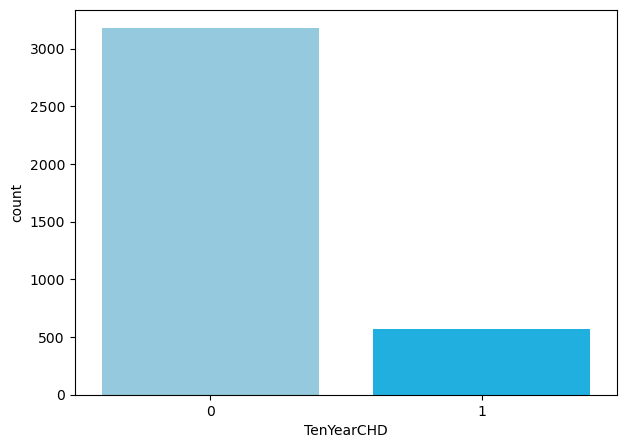

The count plot shows a high imbalance in the dataset where the majority of individuals (over 3000) do not have heart disease (label 0) while only a small number (around 500) have heart disease (label 1)


In [8]:
plt.figure(figsize=(7, 5))
sns.countplot(x='TenYearCHD', data=disease_df,hue='TenYearCHD',
             palette=['skyblue','deepskyblue'],legend=False)
plt.show()
print("The count plot shows a high imbalance in the dataset where the majority of individuals (over 3000) do not have heart disease (label 0) while only a small number (around 500) have heart disease (label 1)")

#### 4.2: Target Variable Distribution (Percentage)

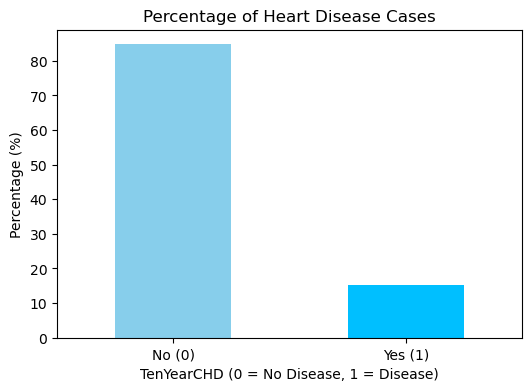

In [9]:
percentages = disease_df["TenYearCHD"].value_counts(normalize=True) * 100

plt.figure(figsize=(6, 4))
percentages.plot(kind="bar", color=["skyblue", "deepskyblue"])
plt.title("Percentage of Heart Disease Cases")
plt.xlabel("TenYearCHD (0 = No Disease, 1 = Disease)")
plt.ylabel("Percentage (%)")
plt.xticks(ticks=[0, 1], labels=["No (0)", "Yes (1)"], rotation=0)
plt.show()

# Step:5 Fitting Logistic Regression Model for Heart Disease Prediction

#### We will create a simple logistic regression model for prediction.

#### logreg=LogisticRegression(): This creates an instance of the LogisticRegression model.
#### logreg.fit(X_train, y_train): This trains the logistic regression model using the training data (X_train for features and y_train for the target).
#### y_pred=logreg.predict(X_test): This uses the trained logistic regression model to make predictions on the test set (X_test). The predicted values are stored in y_pred.

## Model 1: Default / Baseline

In [10]:
from sklearn.linear_model import LogisticRegression

logreg_baseline = LogisticRegression(random_state=4)
logreg_baseline.fit(X_train, y_train)
y_pred_baseline = logreg_baseline.predict(X_test)

## Model 2: Balanced Model

In [11]:
from sklearn.linear_model import LogisticRegression

logreg_balanced = LogisticRegression(class_weight='balanced', random_state=4)
logreg_balanced.fit(X_train, y_train)
y_pred_balanced = logreg_balanced.predict(X_test)

# Step:6 Evaluating Logistic Regression Model



In [12]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, recall_score

# Calculate metrics
acc_before = accuracy_score(y_test, y_pred_baseline)
rec_before = recall_score(y_test, y_pred_baseline, pos_label=1)

acc_after = accuracy_score(y_test, y_pred_balanced)
rec_after = recall_score(y_test, y_pred_balanced, pos_label=1)

# Print the values
print(
    f"Baseline Model  -> Accuracy: {acc_before:.2%}, Recall (Sick Detected): {rec_before:.2%}"
)
print(
    f"Balanced Model  -> Accuracy: {acc_after:.2%}, Recall (Sick Detected): {rec_after:.2%}"
)



Baseline Model  -> Accuracy: 84.90%, Recall (Sick Detected): 8.00%
Balanced Model  -> Accuracy: 67.14%, Recall (Sick Detected): 72.00%


## Plot comparison bar chart

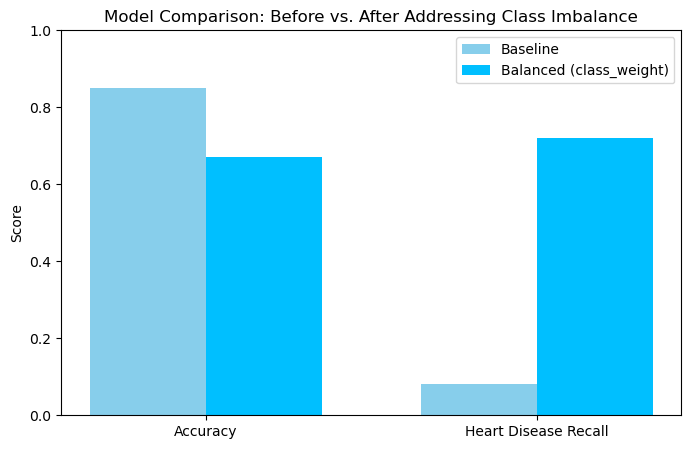

In [13]:
metrics = ["Accuracy", "Heart Disease Recall"]
baseline_scores = [acc_before, rec_before]
balanced_scores = [acc_after, rec_after]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width / 2, baseline_scores, width, label="Baseline", color="skyblue")
plt.bar(
    x + width / 2,
    balanced_scores,
    width,
    label="Balanced (class_weight)",
    color="deepskyblue",
)

plt.ylabel("Score")
plt.title("Model Comparison: Before vs. After Addressing Class Imbalance")
plt.xticks(x, metrics)
plt.ylim(0, 1.0)
plt.legend()
plt.show()

## Plotting Confusion Matrix

#### Confusion Matrix is a performance evaluation tool used to assess the accuracy of a classification model. It is used to evaluate the performance of our logistic regression model in predicting heart disease helping us understand how well the model distinguishes between positive and negative cases.

#### cm=confusion_matrix(y_test, y_pred): Compute confusion matrix by comparing the actual values (y_test) with the predicted values(y_pred). It returns a 2x2 matrix showing true positives, true negatives, false positives and false negatives.

The details for confusion matrix is =
              precision    recall  f1-score   support

           0       0.93      0.66      0.77       951
           1       0.28      0.72      0.41       175

    accuracy                           0.67      1126
   macro avg       0.60      0.69      0.59      1126
weighted avg       0.83      0.67      0.72      1126



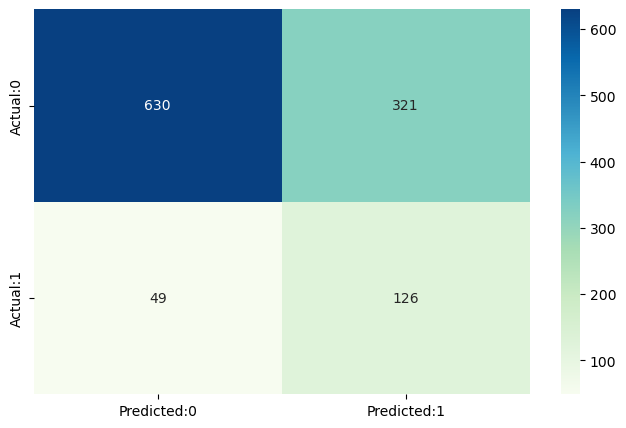

By applying class balancing, the model's recall for high-risk patients (class 1) increased from 8% to 72% (detecting 126 out of 175 heart patients). While overall accuracy is 67%, this trade-off significantly minimizes critical false negatives in clinical screening.


In [14]:
from sklearn.metrics import confusion_matrix, classification_report

print('The details for confusion matrix is =')
print (classification_report(y_test, y_pred_balanced))

cm = confusion_matrix(y_test, y_pred_balanced)
conf_matrix = pd.DataFrame(data = cm, 
                           columns = ['Predicted:0', 'Predicted:1'], 
                           index =['Actual:0', 'Actual:1'])

plt.figure(figsize = (8, 5))
sns.heatmap(conf_matrix, annot = True, fmt = 'd', cmap = "GnBu")

plt.show()
print(
    "By applying class balancing, the model's recall for high-risk patients (class 1) increased from 8% to 72% (detecting 126 out of 175 heart patients). While overall accuracy is 67%, this trade-off significantly minimizes critical false negatives in clinical screening."
)